Academic Integrity and Learning Statement

By submitting my work, I confirm that:

1. The code, analysis, and documentation in this notebook are my own work and reflect my own understanding.
2. I am prepared to explain all code and analysis included in this submission.

If I used assistance (e.g., AI tools, tutors, or other resources), I have:

- Clearly documented where and how external tools or resources were used in my solution.
- Included a copy of the interaction (e.g., AI conversation or tutoring notes) in an appendix.

I acknowledge that:

- I may be asked to explain any part of my code or analysis during evaluation.
- Misrepresenting assisted work as my own constitutes academic dishonesty and undermines my learning.


In [65]:
# Import all librairies
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import random

%matplotlib inline

Before I start I like to upload all my libraries at the top of the page so I wouldn't forget them later and also to be able to see clearly what i'm using and what i needed in the project.

# Task A: An overview of the dataset

1. **Import the data as a Pandas DataFrame and name it as df:**

In [2]:
df = pd.read_csv("p1_communes.csv") # Load the dataset

2. **Check the number of rows and columns:**

In [3]:
df.shape

(2202, 17)

This dataframe contains 2202 rowns and 17 columns.

3. **Display the first few entries of the DataFrame:**

In [4]:
df.head(7)

,Canton,Commune,Language,Residents,Population density per km²,0-19 years,20-64 years,65 years or over,Private households,Surface area in km²,Settlement area,Agricultural area,Wooded area,Unproductive area,East coordinate,North coordinate,Elevation
0,ZH,Aeugst am Albis,de,1982,250.568900,19.677094,62.764884,17.558022,835,7.91,12.658228,51.139241,30.886076,5.316456,2679300,1235700,673
1,ZH,Affoltern am Albis,de,12229,1154.768650,20.508627,61.329626,18.161747,5348,10.59,30.674264,40.170940,28.205128,0.949668,2676800,1236800,502
2,ZH,Bonstetten,de,5548,746.702557,23.666186,60.310022,16.023792,2325,7.43,15.456989,55.510753,28.629032,0.403226,2677800,1241000,583
3,ZH,Hausen am Albis,de,3701,272.132353,21.804918,60.686301,17.508781,1546,13.60,12.692590,55.906090,28.833456,2.567865,2682900,1233100,653
4,ZH,Hedingen,de,3734,571.822358,21.772898,61.756829,16.470273,1540,6.53,19.817073,46.341463,33.231707,0.609756,2676400,1239000,543
5,ZH,Kappel am Albis,de,1157,146.085859,25.237684,60.760588,14.001729,465,7.92,8.312020,69.948849,20.588235,1.150895,2682400,1231300,559
6,ZH,Knonau,de,2373,366.769706,23.893805,61.061947,15.044248,925,6.47,18.027735,62.249615,17.103236,2.619414,2677500,1230900,454


4. **Obtain the index labels, and then show the column names as a list:**

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2202 entries, 0 to 2201
Data columns (total 17 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Canton                      2199 non-null   object 
 1   Commune                     2202 non-null   object 
 2   Language                    2191 non-null   object 
 3   Residents                   2202 non-null   int64  
 4   Population density per km²  2202 non-null   float64
 5   0-19 years                  2202 non-null   float64
 6   20-64 years                 2202 non-null   float64
 7   65 years or over            2202 non-null   float64
 8   Private households          2202 non-null   int64  
 9   Surface area in km²         2202 non-null   float64
 10  Settlement area             2202 non-null   float64
 11  Agricultural area           2202 non-null   float64
 12  Wooded area                 2202 non-null   float64
 13  Unproductive area           2202 

5. **Check the data type for each column:**

In [6]:
df.dtypes

Canton                         object
Commune                        object
Language                       object
Residents                       int64
Population density per km²    float64
0-19 years                    float64
20-64 years                   float64
65 years or over              float64
Private households              int64
Surface area in km²           float64
Settlement area               float64
Agricultural area             float64
Wooded area                   float64
Unproductive area             float64
East coordinate                 int64
North coordinate                int64
Elevation                       int64
dtype: object

6. **Check if there are any missing values and show the rows that contain the missing values.:**

In [7]:
df.isnull().sum()

Canton                         3
Commune                        0
Language                      11
Residents                      0
Population density per km²     0
0-19 years                     0
20-64 years                    0
65 years or over               0
Private households             0
Surface area in km²            0
Settlement area                0
Agricultural area              0
Wooded area                    0
Unproductive area              0
East coordinate                0
North coordinate               0
Elevation                      0
dtype: int64

In [8]:
np.where(df.isnull()) # This shows the location of the missing values

(array([ 155,  156,  157,  158,  440,  440,  704,  704,  757,  757, 1133,
        1165, 1626, 2079]),
 array([2, 2, 2, 2, 0, 2, 0, 2, 0, 2, 2, 2, 2, 2]))

So according to the two used functions there is 3 missing values in the column canton rows 441, 705 and 758. There is also 11 values missing in the column language in the rows: 156, 157, 158, 159, 441, 705, 758, 1134, 1166, 1627, 2080.

7. **If necessary remove any observations to ensure that there are no missing values and the values in each column are of the same data type:**

In [9]:
df.dropna(inplace=True)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 2191 entries, 0 to 2201
Data columns (total 17 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Canton                      2191 non-null   object 
 1   Commune                     2191 non-null   object 
 2   Language                    2191 non-null   object 
 3   Residents                   2191 non-null   int64  
 4   Population density per km²  2191 non-null   float64
 5   0-19 years                  2191 non-null   float64
 6   20-64 years                 2191 non-null   float64
 7   65 years or over            2191 non-null   float64
 8   Private households          2191 non-null   int64  
 9   Surface area in km²         2191 non-null   float64
 10  Settlement area             2191 non-null   float64
 11  Agricultural area           2191 non-null   float64
 12  Wooded area                 2191 non-null   float64
 13  Unproductive area           2191 

Since there was 11 missing values in languages and in those same rows the 3 cantons were missing, this rows were removed from the dataset and that's why there is the same count of Non-Null in all columns.

# Task B: numerical summaries, indexing and grouping

1. **Obtain the mean, minimum and maximum value for each column containing numerical data. Your output should preferably show only the three requested statistics and not the full table of descriptive statistics:**

In [11]:
df.describe().loc[["mean", "min", "max"]]

,Residents,Population density per km²,0-19 years,20-64 years,65 years or over,Private households,Surface area in km²,Settlement area,Agricultural area,Wooded area,Unproductive area,East coordinate,North coordinate,Elevation
mean,3865.299863,433.424048,20.585167,60.371180,19.043653,1702.485167,17.97283,14.882541,45.929853,32.575829,6.611777,2.631543e+06,1.202302e+06,768.209493
min,11.000000,0.895037,0.000000,18.181818,6.271186,10.000000,0.31000,0.138897,0.000000,0.000000,0.000000,2.486700e+06,1.077200e+06,200.000000
max,415367.000000,12669.052100,37.777778,77.922078,81.818182,201252.000000,438.63000,97.260274,91.509434,88.235294,95.022860,2.828800e+06,1.294100e+06,3080.000000


2. **List the 10 most populated communes, ordered by their number of residents:**

In [12]:
df_rez= df[["Residents", "Commune"]].copy()
df_top_rez= df_rez.sort_values("Residents", ascending=False).head(10).copy()
df_top_rez

,Residents,Commune
154,415367,Zürich
2124,201818,Genève
910,172258,Basel
1749,139111,Lausanne
194,133883,Bern
141,111851,Winterthur
535,81691,Luzern
1053,75833,St. Gallen
1582,63185,Lugano
207,55159,Biel/Bienne


I started by isolating the two columns we want to compare in a seperate dataframe using `.copy()`, than used the `.sort_values()` function we saw in the course to sort them from top to bottom, than show only the top 10 using `.head(10)`.

3. **List the 10 least populated communes, ordered by their number of residents:**

In [13]:
df_bottom_rez= df_rez.sort_values("Residents", ascending=True).head(10).copy()
df_bottom_rez

,Residents,Commune
1546,11,Corippo
875,28,Kammersrohr
2011,33,Bister
366,36,Schelten
370,41,Rebévelier
485,45,Berken
1629,45,Cerentino
342,46,Clavaleyres
1627,46,Bosco/Gurin
1160,46,Lohn (GR)


Same logic as the previous question the only difference is `ascending=True` and the values were sorted from least to most populated communes. 

The goal of isolating the two columns is for the visual effect, to make the notebook lighter and easier to read. However this can be done to the original dataframe as you can see down bellow:

In [14]:
df_top= df.sort_values("Residents", ascending=False).head(10).copy()
df_bottom= df.sort_values("Residents", ascending=True).head(10).copy()
df_bottom

,Canton,Commune,Language,Residents,Population density per km²,0-19 years,20-64 years,65 years or over,Private households,Surface area in km²,Settlement area,Agricultural area,Wooded area,Unproductive area,East coordinate,North coordinate,Elevation
1546,TI,Corippo,it,11,1.426719,0.000000,18.181818,81.818182,10,7.71,0.259740,3.506494,64.935065,31.298701,2708100,1121500,1134
875,SO,Kammersrohr,de,28,29.473684,10.714286,67.857143,21.428571,12,0.95,3.191489,56.382979,40.425532,0.000000,2611700,1233700,618
2011,VS,Bister,de,33,5.679862,9.090909,60.606061,30.303030,16,5.81,1.206897,15.862069,42.586207,40.344828,2648200,1134500,1777
366,BE,Schelten,de,36,6.474820,22.222222,63.888889,13.888889,13,5.56,1.985560,38.628159,59.205776,0.180505,2608500,1242500,907
370,BE,Rebévelier,de,41,11.549296,29.268293,46.341463,24.390244,16,3.55,0.564972,59.887006,39.548023,0.000000,2580000,1237500,990
485,BE,Berken,de,45,32.374101,11.111111,62.222222,26.666667,21,1.39,11.428571,52.857143,30.000000,5.714286,2620500,1230500,441
1629,TI,Cerentino,it,45,2.238806,13.333333,53.333333,33.333333,26,20.10,1.343284,4.975124,71.741294,21.940299,2685300,1128800,1498
342,BE,Clavaleyres,de,46,46.000000,13.043478,58.695652,28.260870,17,1.00,5.000000,80.000000,15.000000,0.000000,2573500,1194200,466
1627,TI,Bosco/Gurin,it,46,2.089959,8.695652,60.869565,30.434783,25,22.01,0.635786,24.386921,30.881017,44.096276,2681100,1130000,2019
1160,GR,Lohn (GR),rm,46,5.630355,13.043478,63.043478,23.913043,19,8.17,1.105651,57.371007,34.275184,7.248157,2752200,1168600,1760


4. **Group the communes by canton and save them into separate .csv files:**

In [15]:
for val, group in df.groupby("Canton"):
  safe_val = str(val)
  filename = f'{safe_val}.csv'
  group.to_csv(filename, index=False)

In this one I had to use a loop of the dataframe grouped by canton, than extracting the value (name) of the canton and using it as a file name.

5. **Compute the population density at the canton level and rank the cantons from most dense to least dense:**

In [16]:
density_canton = df.groupby("Canton")["Residents"].sum()/df.groupby("Canton")["Surface area in km²"].sum()
print(density_canton.sort_values(ascending=False))


Canton
BS    5271.069012
GE    2031.893255
ZH     948.443099
ZG     612.265881
BL     556.593969
AG     486.145498
SO     345.618319
TG     320.320701
LU     286.577848
VD     283.275259
SH     274.989938
SG     260.210650
NE     249.037193
AR     227.450173
FR     201.503947
SZ     186.964795
NW     179.095881
BE     177.054876
TI     131.670991
AI      93.605056
JU      87.558884
OW      78.733719
VS      65.977584
GL      59.355076
UR      34.457223
GR      29.047582
dtype: float64


When comparing residents per commune, the top 3 were Zurich, Geneva and Basel. Howere when comparing the population density Basel and Zurich switched places and that's due to the surface area of each canton.

6. **Compute the number of communes in each canton where more than 50 percent of their populations are aged between 20 and 64 years old:**

In [17]:
df.loc[df["20-64 years"]>50,["Commune","Canton"]].groupby("Canton").count()

,Commune
Canton,
AG,210
AI,6
AR,20
BE,339
BL,86
BS,3
FR,131
GE,45
GL,3


7. **Compute the difference between the maximum and minimum elevations for each canton:**

In [18]:
Elevation_range=df.groupby("Canton")["Elevation"].max()-df.groupby("Canton")["Elevation"].min()
Elevation_range

Canton
AG     408
AI     432
AR     488
BE    2025
BL     599
BS     184
FR     988
GE     116
GL     587
GR    2017
JU     606
LU     944
NE     708
NW    1010
OW     501
SG    1429
SH     314
SO     675
SZ    1271
TG     318
TI    2044
UR    1871
VD    1292
VS    2610
ZG     560
ZH     521
Name: Elevation, dtype: int64

In [19]:
Elevation_range.sort_values(ascending=False).head(5)

Canton
VS    2610
TI    2044
BE    2025
GR    2017
UR    1871
Name: Elevation, dtype: int64

The top 5 cantons that have the largest range of elevations are: Valais, Ticino, Bern, Graubünden and Uri.

# Task C: visualizations

1. **Horizontal bar plot of the top 10 populated communes:**

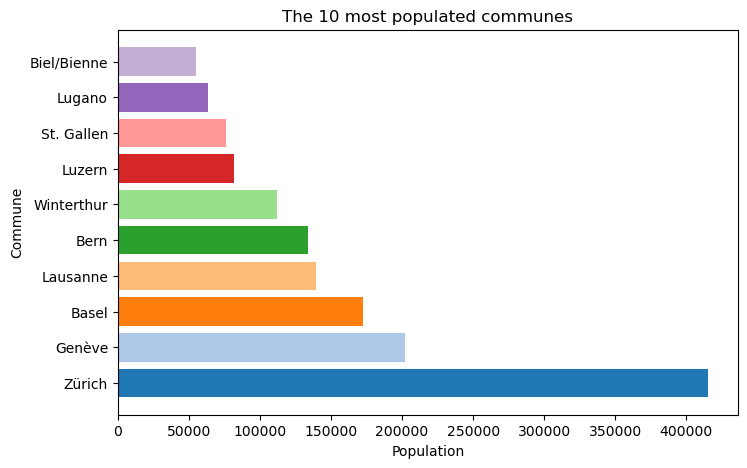

In [20]:
commune = df_top["Commune"] 
residents = df_top["Residents"]  

plt.figure(figsize=(8, 5))
colormap = plt.cm.tab20(range(0, len(commune)))
plt.barh(commune, residents, color=colormap) 
plt.title("The 10 most populated communes")
plt.xlabel("Population")
plt.ylabel("Commune")
plt.show()

2. **Stacked horizontal bar chart of the top 10 populated by area type:**

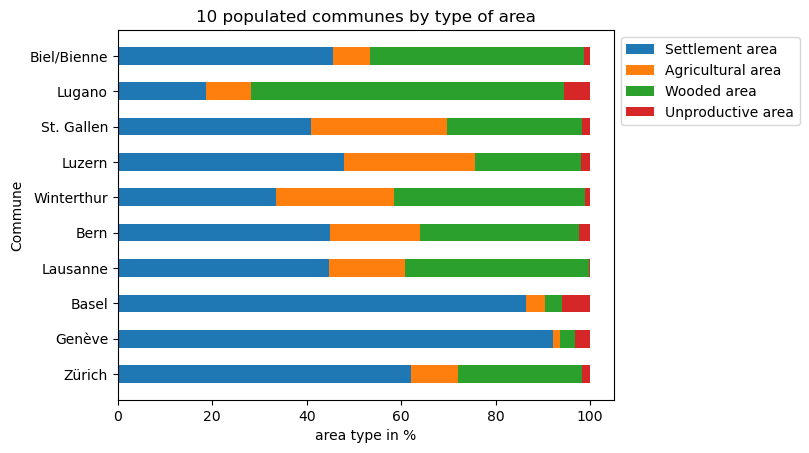

In [21]:
width = 0.5
p1 = plt.barh(df_top["Commune"], df_top["Settlement area"], width)
area_ag = df_top["Settlement area"] + df_top["Agricultural area"]
p2 = plt.barh(df_top["Commune"], df_top["Agricultural area"], width, left=df_top["Settlement area"])
area_wood = area_ag + df_top["Wooded area"]
p3 = plt.barh(df_top["Commune"], df_top["Wooded area"], width, left=area_ag)
area_unprod = area_wood + df_top["Unproductive area"]
p4 = plt.barh(df_top["Commune"], df_top["Unproductive area"], width, left=area_wood)
     
plt.legend(["Settlement area", "Agricultural area", "Wooded area", "Unproductive area"],bbox_to_anchor=(1, 1))
plt.xlabel("area type in %")
plt.ylabel("Commune")
plt.title("10 populated communes by type of area")
plt.show()

The top 3 biggest communes by population has the biggest settlement area due to the number of it's population which makes perfect sense. Lugano has the biggest wooded area. And Lausanne has the least unproductive area. 

3. **Histogram of the number of communes and their proportions of young residents (0-19yrs):**

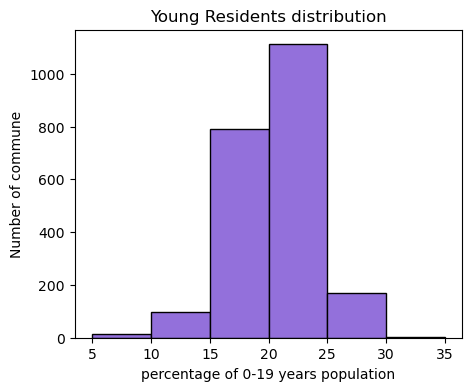

In [22]:
# Check values of the intervals:
a = df.loc[df["0-19 years"]<=10,["Commune"]].count() - df.loc[df["0-19 years"]<5,["Commune"]].count()
b = df.loc[df["0-19 years"]<=15,["Commune"]].count() - df.loc[df["0-19 years"]<10,["Commune"]].count()
c = df.loc[df["0-19 years"]<=20,["Commune"]].count() - df.loc[df["0-19 years"]<15,["Commune"]].count()
d = df.loc[df["0-19 years"]<=25,["Commune"]].count() - df.loc[df["0-19 years"]<20,["Commune"]].count()
e = df.loc[df["0-19 years"]<=30,["Commune"]].count() - df.loc[df["0-19 years"]<25,["Commune"]].count()
f = df.loc[df["0-19 years"]<=35,["Commune"]].count() - df.loc[df["0-19 years"]<30,["Commune"]].count()

# Histogram plot
plt.figure(figsize=(5, 4))
interv = [5, 10, 15, 20, 25, 30, 35]
plt.hist(df["0-19 years"], bins=interv,color="mediumpurple", edgecolor="black")
plt.xlabel("percentage of 0-19 years population") # X axis label
plt.ylabel("Number of commune") # Y axis label
plt.title("Young Residents distribution") # Title
plt.show()

4. **Investigate the distributions of languages for the 0-19 years age group:**

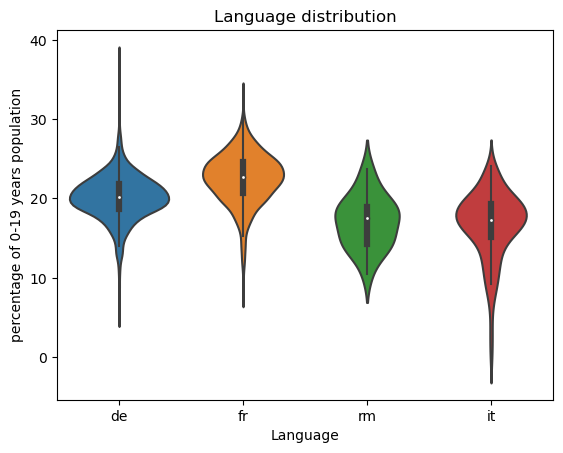

In [23]:
sns.violinplot(x = "Language", y = "0-19 years", data = df)
plt.ylabel("percentage of 0-19 years population")
plt.title("Language distribution") # Title
plt.show()

I'm not sure about this answer but I would say the mean of the french speaking population (0-19 years) is around 24% which is higher than the other languages. The top spoken languages are french and swiss german. I might add that the dataframe contains the percentage of the 0-19 population and the language spoken at that commune/canton in general. which means the focus of the dataframe is the general knowledge about each commune, not only the languages spoken and not including the languages taught in school. Therefore we can't base the conclusion of the language distribution on this specific dataset.

5. **Investigate the distribution languages over all age groups:**

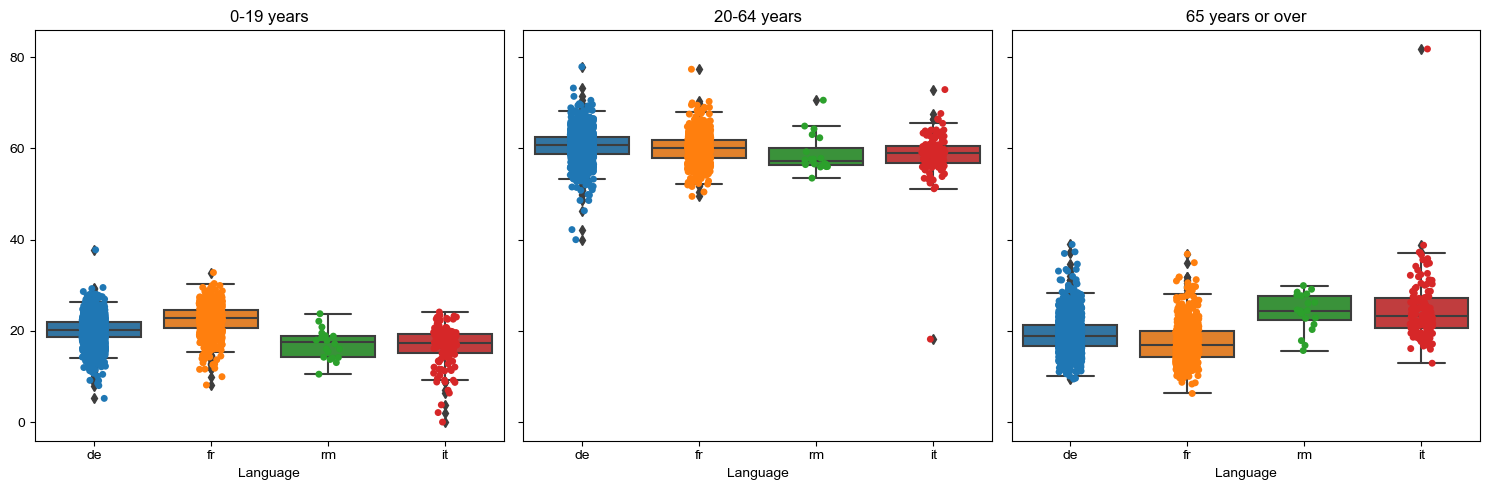

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
sns.set_style("ticks")
sns.boxplot(ax=axes[0], x="Language", y="0-19 years", data = df)
sns.stripplot(ax=axes[0], x="Language", y="0-19 years", data = df)
axes[0].set_title("0-19 years")
sns.boxplot(ax=axes[1], x="Language", y="20-64 years", data = df)
sns.stripplot(ax=axes[1], x="Language", y="20-64 years", data = df)
axes[1].set_title("20-64 years")
sns.boxplot(ax=axes[2], x="Language", y="65 years or over", data = df)
sns.stripplot(ax=axes[2], x="Language", y="65 years or over", data = df)
axes[2].set_title("65 years or over")
plt.setp(axes, ylabel="")
fig.tight_layout()
plt.show()

Same comment here as the previous one about drawing a factual conclusion for this dataset is not enough. However from what we see, from the mean value of each category, for 0-19 years the French is first, for 20-64 Swiss German is slightly higher, and for over 65 Romansh is taking the lead followed by Italian.

6. **The pairplot plots to visually investigate the relation between the Agricultural area of communes and their Settlement area, Wooded area and the Unproductive area:**

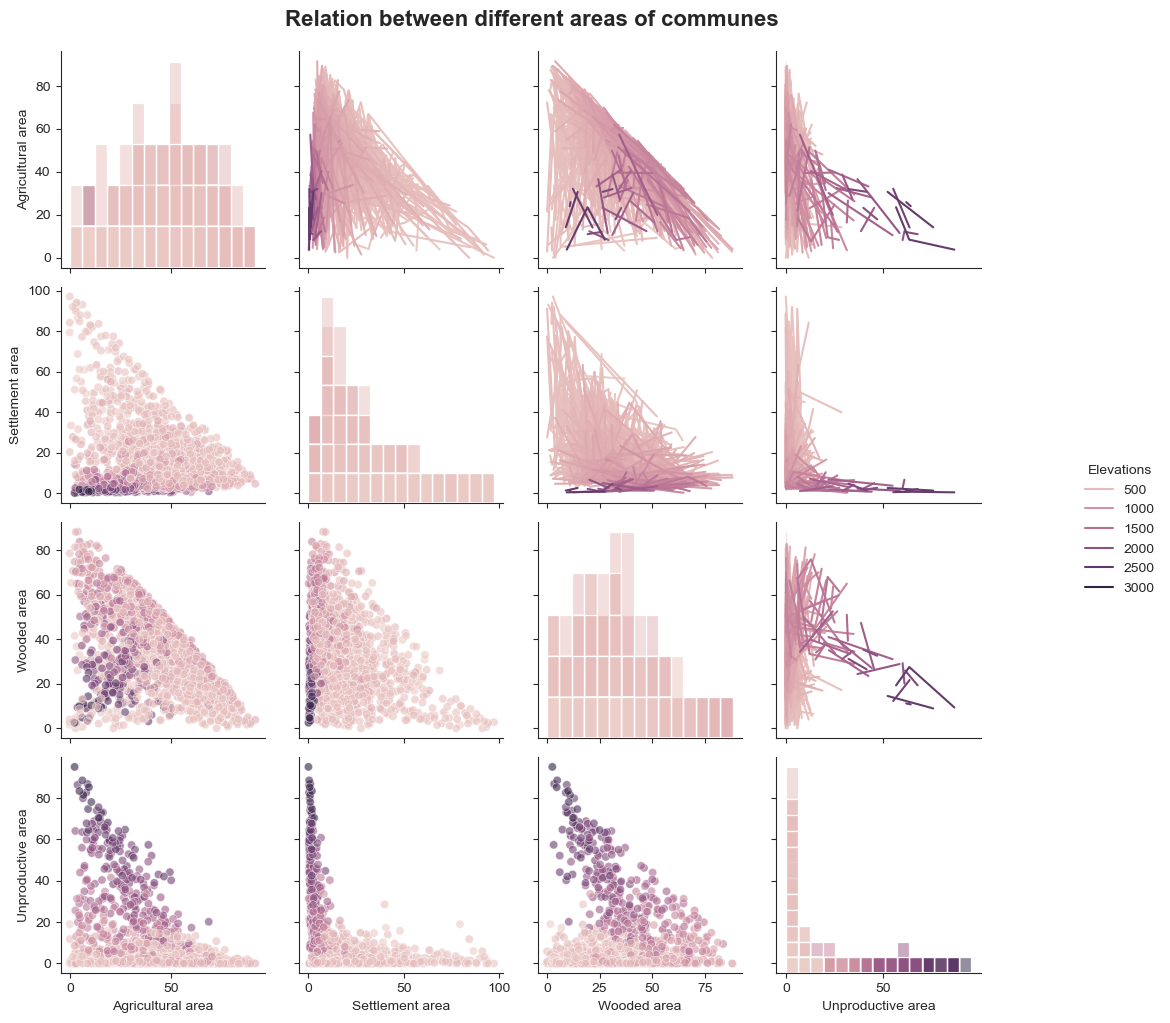

In [46]:
area = [
    "Agricultural area", 
    "Settlement area", 
    "Wooded area", 
    "Unproductive area"
]
g = sns.PairGrid(
    df, 
    vars=area, 
    diag_sharey=False, 
    hue="Elevation"
)
g.map_lower(sns.scatterplot, alpha=0.6)
g.map_diag(sns.histplot, bins = 15)
g.map_upper(sns.lineplot)
g.add_legend(title="Elevations", loc= "center left", bbox_to_anchor=(1, 0.5))
g.fig.suptitle("Relation between different areas of communes", fontsize=16, fontweight="bold", y=1.02)
plt.show()

The linear relations I could see from this graphs is that the agricultral areas tend to had less presence of the wooded area and settlement area and vice versa.

7. **A map of Switzerland using the East and North coordinates of communes:**

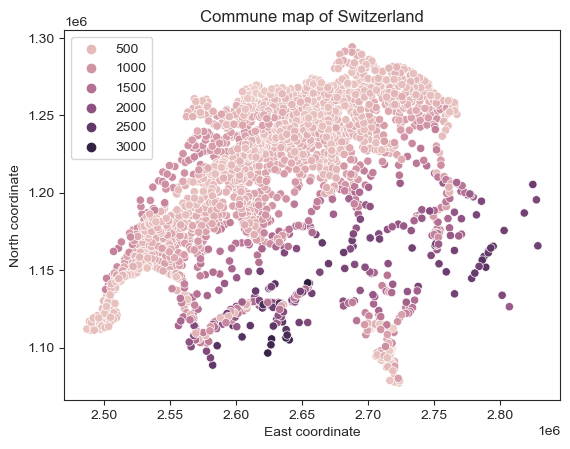

In [52]:
sns.scatterplot(data = df, x="East coordinate", y="North coordinate", hue="Elevation") 
plt.legend(loc= "upper left")
plt.title("Commune map of Switzerland")
plt.show()

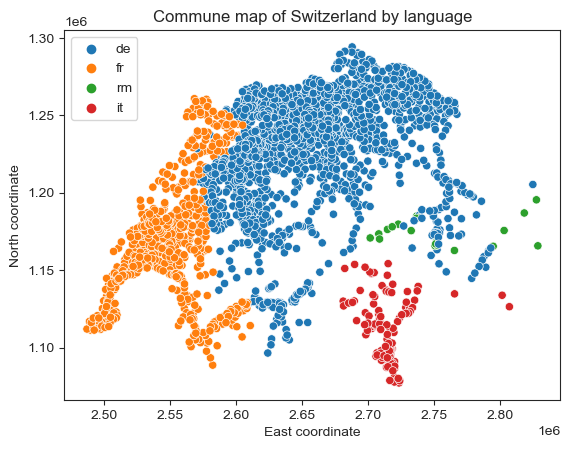

In [54]:
sns.scatterplot(data = df, x="East coordinate", y="North coordinate", hue="Language") 
plt.legend(loc= "upper left")
plt.title("Commune map of Switzerland by language")
plt.show()

For the first plot, the map is darker in Swiss Alpes then the Central Plateau the Jura which is accurate with the different elevations. The sencond plots devides Switzerland by language into 4 regions. The west is french speaking, north and central south is german speaking and the south east is italien speaking, while romansh is more located in the east north and some parts of the german speaking territories.

8. **Two plots from the previous task as subplots (with 1 row and 2 columns):**

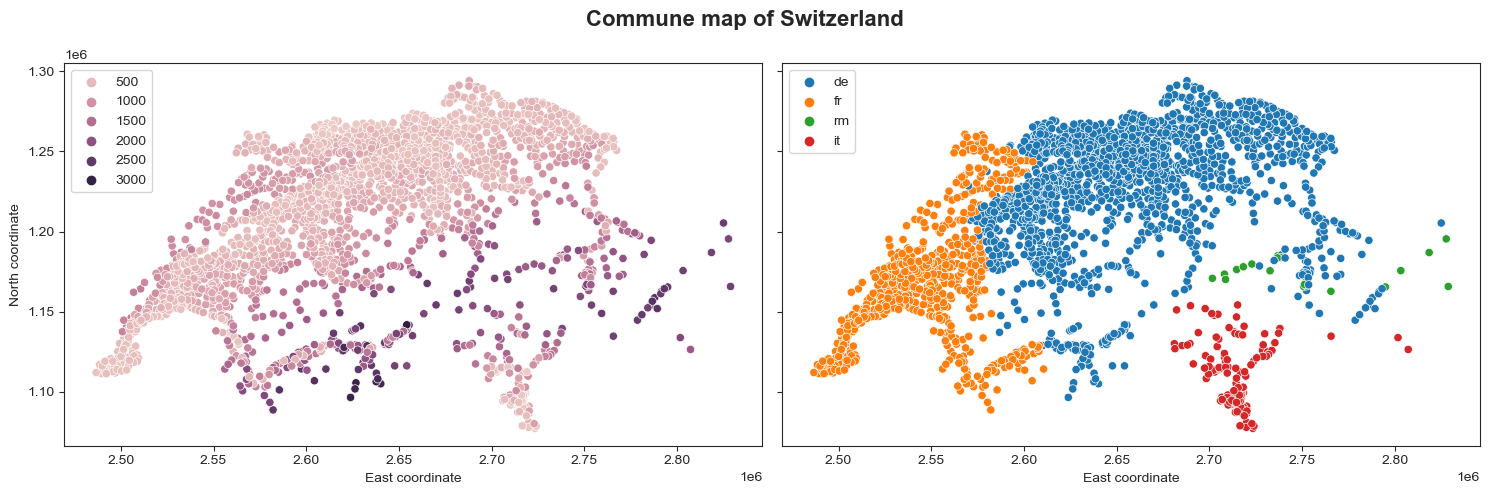

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
sns.scatterplot(ax=axes[0], data = df, x="East coordinate", y="North coordinate", hue="Elevation")
axes[0].legend(loc= "upper left")
sns.scatterplot(ax=axes[1], data = df, x="East coordinate", y="North coordinate", hue="Language")
axes[1].legend(loc= "upper left")
fig.suptitle("Commune map of Switzerland", fontsize=16, fontweight="bold")
fig.tight_layout()
plt.show()

# Task D: Probabilities

Compute the probability that a randomly selected commune with elevation over 2000 is from the canton of Valais: 
Let's use the course formula for conditional probability. Let P(A) be the probability of the commune being in the valais and P(B) is the commune being on an elevation over 2000: 
$$
P(\text{Valais} \mid \text{Elevation} > 2000)
=
\frac{P(\text{Valais} \cap \text{Elevation} > 2000)}
{P(\text{Elevation} > 2000)}
$$

In [78]:
num_commune_valais=df.loc[(df["Canton"]=="VS")&(df["Elevation"]>2000), "Commune"].count()
num_commune=df.loc[(df["Elevation"]>2000), "Commune"].count()
p_ab = num_commune_valais/num_commune
p_ab

0.5104166666666666

# Task E: Matrices

Define a data frame matrix whose rows correspond to communes and the columns to the cantons: this means that the index of the new dataframe/matrix are the communes and the headers are the canton with 1 where the commune is in the canton and zero if it's not. This means we will have a matrix 2191x26 if we don't want to repeat the canton each time or 2191x2191 if the canton is repeated:

In [99]:
# Matrix 2191x2191:
M = pd.DataFrame(0, index=df["Commune"], columns=df["Canton"]) 
for commune, canton in zip(df["Commune"], df["Canton"]):
    M.loc[commune, canton] = 1
M

Canton,ZH,ZH,ZH,ZH,ZH,ZH,ZH,ZH,ZH,ZH,...,JU,JU,JU,JU,JU,JU,JU,JU,JU,JU
Commune,,,,,,,,,,,,,,,,,,,,,
Aeugst am Albis,1,1,1,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
Affoltern am Albis,1,1,1,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
Bonstetten,1,1,1,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
Hausen am Albis,1,1,1,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
Hedingen,1,1,1,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Vendlincourt,0,0,0,0,0,0,0,0,0,0,...,1,1,1,1,1,1,1,1,1,1
Basse-Allaine,0,0,0,0,0,0,0,0,0,0,...,1,1,1,1,1,1,1,1,1,1
Clos du Doubs,0,0,0,0,0,0,0,0,0,0,...,1,1,1,1,1,1,1,1,1,1


In [100]:
# Matrix 2191x26:
MM = pd.DataFrame(0, index=df["Commune"], columns=df["Canton"].unique())
for commune, canton in zip(df["Commune"], df["Canton"]):
    MM.loc[commune, canton] = 1
MM

,ZH,BE,LU,UR,SZ,OW,NW,GL,ZG,FR,...,SG,GR,AG,TG,TI,VD,VS,NE,GE,JU
Commune,,,,,,,,,,,,,,,,,,,,,
Aeugst am Albis,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Affoltern am Albis,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Bonstetten,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Hausen am Albis,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Hedingen,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Vendlincourt,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
Basse-Allaine,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
Clos du Doubs,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


# Appendix

I used most of the functions seen in the course, the ones I couldn’t find, I google either by name to get the syntax or what I wanted them to do exactly. Most of the functions I found are on forums or in youtube videos. For checking syntax issues I frequently checked Stack Overflow (https://stackoverflow.com) and Geeks for Geeks (https://www.geeksforgeeks.org). Here’s the links to the websites I used, for the questions I had to google:

(A.6) Location of the missing values: I googled to find another option of `df.isnul()` since it only showed the columns and not the rows, I found it in a youtube video: https://www.youtube.com/watch?v=nLqkyKZZXUs
`np.where(df.isnull())`

(B.1) https://www.statology.org/pandas-describe-only-mean-std/ 
`df.describe().loc[["mean", "min", "max"]]`: This was to isolate the values I wanted in `describe()`

(B.4) https://www.youtube.com/shorts/-O3QP50SxSI
`for val, group in df.groupby("Canton"):
  safe_val = str(val)
  filename = f'{safe_val}.csv'
  group.to_csv(filename, index=False)`
This was to automate the name of the saved file

(C.5) https://dev.to/thalesbruno/subplotting-with-matplotlib-and-seaborn-5ei8
This one helped me with the different titles in each subplot

(C.6) https://seaborn.pydata.org/generated/seaborn.PairGrid.html
I used ‘PairGrid’ intead of  `pairplot` to be able to choose which plots I want. I had to look up the syntax since I haven’t used it before

(E) https://stackoverflow.com/questions/49783594/for-loop-and-zip-in-python
I used this one to be able to include two columns in my condition.